# Horizon and anchor sensitivity

## The question

**How far into the future, and how far along a branch, does a fate score look?**

An annotated branch contains early, intermediate and later cells. Calling some of them fate anchors specifies the event whose reach is measured. The effective horizon specifies the strength of distance discounting. These are scientific choices, not only numerical tuning parameters.

An apparent preference for one branch may therefore reflect easier access to its anchors. We deliberately make one branch longer while preserving a nominally symmetric split, then change horizon and anchor position. The goal is to reveal this dependence before a treatment comparison is interpreted.

## How to read the experiment

Read CFA, DFR and defined-affinity coverage together for each fixed anchor setting. Increasing horizon should not decrease discounted reach on a fixed graph, but conditional affinity can move in either direction in general. Compare anchor settings as different outcome definitions; do not select the combination that makes a desired condition effect largest.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import scCS
from benchmarks.validation import experiments as exp

SEED = 20261117
DATA = ROOT / "data" / "validation"
OUT = ROOT / "tutorial_outputs" / "validation"
OUT.mkdir(parents=True, exist_ok=True)
print("scCS", scCS.__version__)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 4)})

scCS 1.0.1.dev0


## Question
How much of a fate preference reflects path length and anchor placement? A symmetric fork has branch lengths 1 and 3, equal density per unit length and five seeded realizations. We evaluate horizons 16–4096 and four anchor quantiles. A graph step is not a unit of biological time.

The early-anchor comparison is a sensitivity analysis, not an automatic correction. It asks about reaching the entry of an annotated state, whereas late anchors ask about reaching later representatives.


In [3]:
sensitivity = exp.horizon_sensitivity(n_seeds=5)
display(sensitivity.groupby(["q", "h"])[["CFA_A", "DFR", "coverage"]].mean())
sensitivity.to_csv(OUT / "horizon_anchor_sensitivity.csv", index=False)

CFA_A       DFR  coverage
q    h                                 
0.01 16    0.544205  0.753744       1.0
     32    0.543442  0.863470       1.0
     64    0.543053  0.927901       1.0
     128   0.542858  0.962922       1.0
     256   0.542759  0.981194       1.0
     4096  0.542667  0.998809       1.0
0.50 16    0.637330  0.512644       1.0
     32    0.591271  0.704979       1.0
     64    0.566846  0.836192       1.0
     128   0.554312  0.913471       1.0
     256   0.547970  0.955501       1.0
     4096  0.541979  0.997143       1.0
0.90 16    0.675990  0.372664       1.0
     32    0.604361  0.585256       1.0
     64    0.565453  0.748403       1.0
     128   0.545366  0.850977       1.0
     256   0.535186  0.908718       1.0
     4096  0.525568  0.967257       1.0
0.95 16    0.643858  0.314027       1.0
     32    0.570121  0.515788       1.0
     64    0.531056  0.675770       1.0
     128   0.511134  0.778136       1.0
     256   0.501098  0.836288       1.0
     4096  0.491652  0.895601       1.0

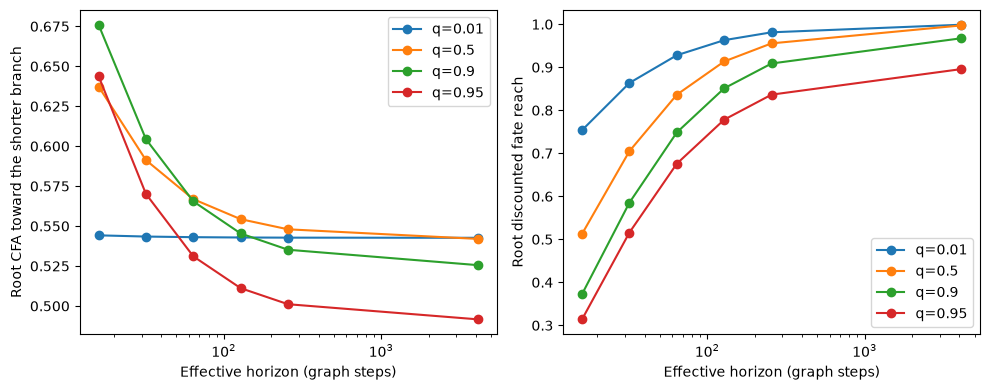

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for q, group in sensitivity.groupby("q"):
    mean = group.groupby("h")[["CFA_A", "DFR"]].mean()
    axes[0].plot(mean.index, mean.CFA_A, marker="o", label=f"q={q}")
    axes[1].plot(mean.index, mean.DFR, marker="o", label=f"q={q}")
for ax in axes:
    ax.set(xscale="log", xlabel="Effective horizon (graph steps)")
    ax.legend()
axes[0].set_ylabel("Root CFA toward the shorter branch")
axes[1].set_ylabel("Root discounted fate reach")
fig.tight_layout()
plt.show()

## Interpretation and reporting
For a fixed graph and anchor set, discounted reach cannot decrease as the horizon grows. Conditional affinity can change because longer paths become less penalized. Report the grid and defined-affinity coverage alongside the primary setting; do not select parameters to maximize a treatment p-value. The production `SingleScorer.sensitivity_analysis()` helper evaluates an equivalent grid without changing the fitted result. See [diagnostics](https://sccs-py.readthedocs.io/en/latest/diagnostics.html).


In [5]:
for _, group in sensitivity.groupby(["seed", "q"]):
    assert np.all(np.diff(group.sort_values("h").DFR) >= -1e-9)
assert sensitivity.residual.max() < 1e-8
print("Reach monotonicity and numerical checks passed.")

Reach monotonicity and numerical checks passed.
